In [1]:
# Cell 1: Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input

# Plotting style
plt.style.use('fivethirtyeight')
print("Libraries loaded successfully.")

Libraries loaded successfully.


Data Integrity Check: Passed (No missing values)
                  Open        High         Low       Close   Adj Close  \
Date                                                                     
2017-11-09  308.644989  329.451996  307.056000  320.884003  320.884003   
2017-11-10  320.670990  324.717987  294.541992  299.252991  299.252991   
2017-11-11  298.585999  319.453003  298.191986  314.681000  314.681000   
2017-11-12  314.690002  319.153015  298.513000  307.907990  307.907990   
2017-11-13  307.024994  328.415009  307.024994  316.716003  316.716003   

                Volume  
Date                    
2017-11-09   893249984  
2017-11-10   885985984  
2017-11-11   842300992  
2017-11-12  1613479936  
2017-11-13  1041889984  


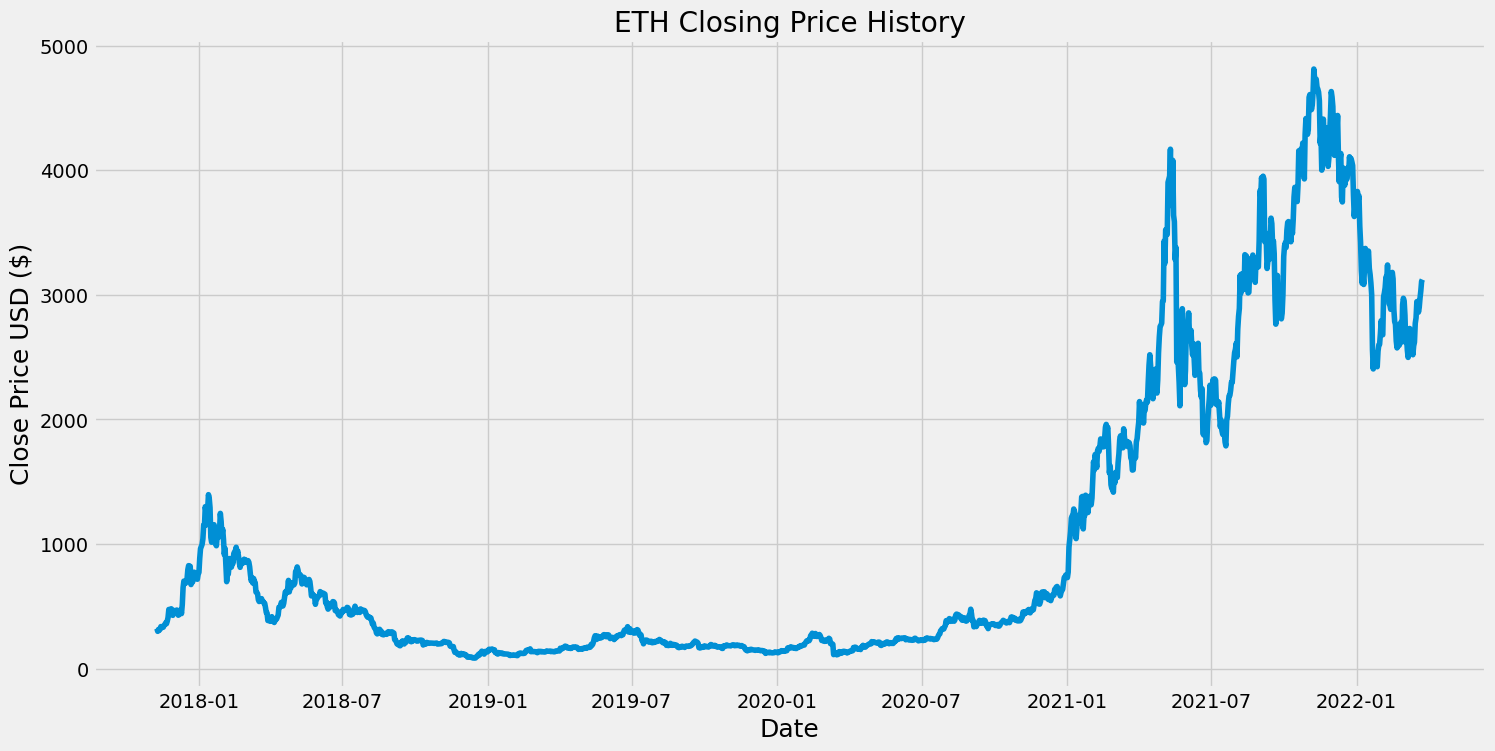

In [2]:
# Cell 2: Load Data
# Load the dataset
df = pd.read_csv('ETH-USD.csv')

# Check for missing values
if df.isnull().values.any():
    print("WARNING: Missing values detected. Dropping...")
    df = df.dropna()
else:
    print("Data Integrity Check: Passed (No missing values)")

# Convert Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Set Date as the index
df.set_index('Date', inplace=True)

# Sort by date to ensure chronological order
df.sort_index(inplace=True)

# Inspect the first few rows
print(df.head())

# Visualize the closing price history
plt.figure(figsize=(16,8))
plt.title('ETH Closing Price History')
plt.plot(df['Close'])
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.show()

In [3]:
# Cell 3: Data Preprocessing

# 1. Select the Feature
# We are strictly using 'Close' price
data = df.filter(['Close'])
dataset = data.values

# 2. Compute Split Point (80% Train / 20% Test)
training_data_len = int(np.ceil(len(dataset) * .8))

# 3. Create Training Set
train_data_unscaled = dataset[0:training_data_len, :]

# 4. Scale the Data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train_data = scaler.fit_transform(train_data_unscaled)

print(f"Training Data Length: {len(scaled_train_data)}")

Training Data Length: 1279


In [4]:
# Cell 4: Create Sequences (Sliding Window)

# Configuration: Look back 60 days to predict the next day
prediction_days = 60

x_train = []
y_train = []

for i in range(prediction_days, len(scaled_train_data)):
    x_train.append(scaled_train_data[i-prediction_days:i, 0])
    y_train.append(scaled_train_data[i, 0])

# Convert to Numpy Arrays
x_train, y_train = np.array(x_train), np.array(y_train)

# Reshape for RNN [Samples, Time Steps, Features]
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

print(f"Final Input Shape: {x_train.shape}")

Final Input Shape: (1219, 60, 1)


In [5]:
# Cell 5: Build Model

model = Sequential()

# Layer 1: SimpleRNN
model.add(Input(shape=(x_train.shape[1], 1)))
model.add(SimpleRNN(units=50, return_sequences=False))
# Layer 2: Dense Output
model.add(Dense(units=1))

# Compile
model.compile(optimizer='adam', loss='mean_squared_error')

print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

None


Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0054
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 3.4672e-04
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2.0621e-04
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 1.5907e-04
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.6585e-04
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.2682e-04
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 1.4857e-04
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2.5053e-04
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.5163e-04
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.5655e-04
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.2052e-04
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.1927e-04
Epoch 13/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 1.1413e-04
Epoch 14/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1.5063e-04
Epoch 15/20
39/39 ━

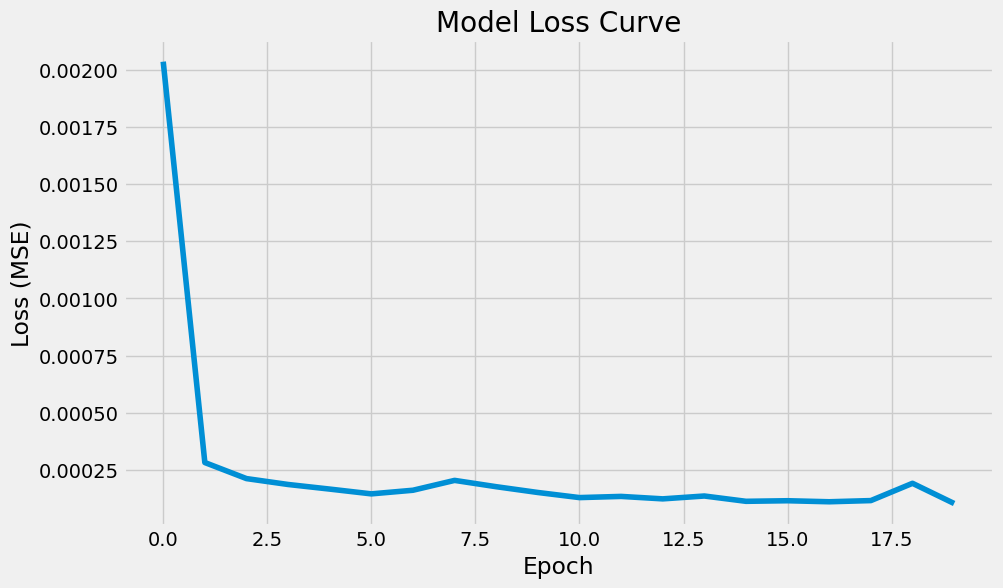

In [6]:
# Cell 6: Training
history = model.fit(x_train, y_train, batch_size=32, epochs=20)

# Plot Training Loss
plt.figure(figsize=(10,6))
plt.plot(history.history['loss'])
plt.title('Model Loss Curve')
plt.ylabel('Loss (MSE)')
plt.xlabel('Epoch')
plt.show()

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

=== ForeQast Baseline Metrics ===
Mean Error (ME): -7.9927
Mean Absolute Error (MAE): 121.8924
Root Mean Squared Error (RMSE): 165.1459
Mean Percentage Error (MPE): -0.4292%
Mean Absolute Percentage Error (MAPE): 4.0219%



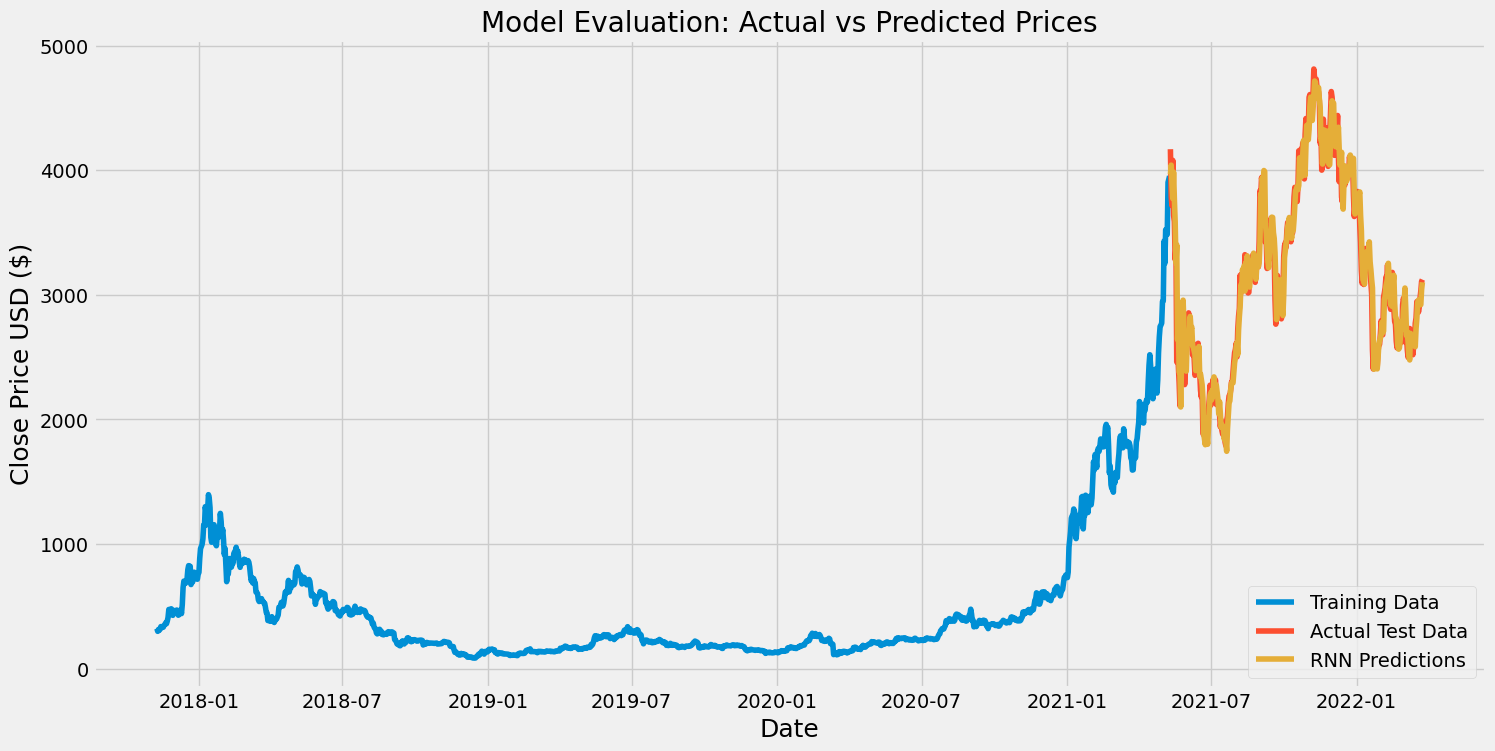

In [7]:
# Cell 7: Evaluation & Metrics

# 1. Prepare Test Data
# We need the last 60 days of the Training set to predict the 1st day of the Test set
test_data_unscaled = dataset[training_data_len - prediction_days: , :]

# Scale using the TRAINING scaler (Do not re-fit!)
test_data = scaler.transform(test_data_unscaled)

x_test = []
y_test = dataset[training_data_len:, :]

for i in range(prediction_days, len(test_data)):
    x_test.append(test_data[i-prediction_days:i, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

# 2. Make Predictions
predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

# 3. Calculate Required Metrics
errors = y_test - predictions
me = np.mean(errors)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mpe = np.mean((y_test - predictions) / y_test) * 100
mape = np.mean(np.abs((y_test - predictions) / y_test)) * 100

print("\n=== ForeQast Baseline Metrics ===")
print(f"Mean Error (ME): {me:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Percentage Error (MPE): {mpe:.4f}%")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.4f}%\n")

# 4. Visual Comparison
# Plot the results
train = data[:training_data_len]
valid = data[training_data_len:].copy()
valid['Predictions'] = predictions

plt.figure(figsize=(16,8))
plt.title('Model Evaluation: Actual vs Predicted Prices')
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.plot(train['Close'], label='Training Data')
plt.plot(valid['Close'], label='Actual Test Data')
plt.plot(valid['Predictions'], label='RNN Predictions')
plt.legend(loc='lower right')
plt.show()